1.Jacobi 迭代解 A x = b。

In [5]:
import numpy as np
def jacobi(A, b, x0, tol=1e-3, max_iter=100):
    """
    Jacobi 迭代法解线性方程组 Ax = b

    参数：
        A: n x n 系数矩阵，二维列表
        b: 长度 n 的右端向量
        x0: 长度 n 的初始猜测向量
        tol: 容差，默认 1e-3
        max_iter: 最大迭代次数，默认 100

    返回：
        x_new: 近似解向量
        k: 实际迭代次数
    """
    n = len(b)                      # 矩阵 A 的行数
    x = x0[:]                       # 复制初始猜测，避免修改原向量
    x_new = [0.0] * n               # 用来存这一轮算出的新值

    for k in range(1, max_iter + 1):
        # 1. 遍历每一行，计算新值
        for i in range(n):
            s = 0.0
            for j in range(n):
                if j != i:
                    s += A[i][j] * x[j]   # 注意：这里用的是上一轮的 x
            x_new[i] = (b[i] - s) / A[i][i]  # Jacobi 核心公式

        # 2. 计算误差，判断是否收敛
        error = 0.0
        for i in range(n):
            error = max(error, abs(x_new[i] - x[i]))  # max(|x_new - x_old|)

        # 3. 检查停止条件
        if error < tol:
            return x_new, k          # 满足容差，返回结果和迭代次数

        # 4. 更新旧值，准备下一轮迭代
        x = x_new[:]                 # 或者 for i in range(n): x[i] = x_new[i]

    # 达到最大迭代次数仍未收敛
    return x_new, max_iter

  # 故意把 max_iter 设为 1，检查代码能不能正确退出
A = np.array([[4.0, 1.0], [1.0, 3.0]])
b = np.array([1.0, 2.0])
x0 = np.array([0.0, 0.0])
x, iterations = jacobi(A, b, x0, tol=1e-6, max_iter=1)
print(f"max_iter=1 时，迭代次数为 {iterations}，输出解 {x}")

max_iter=1 时，迭代次数为 1，输出解 [np.float64(0.25), np.float64(0.6666666666666666)]


n= 10 | 时间=0.0015秒 | 迭代次数=41
n= 50 | 时间=0.1700秒 | 迭代次数=166
n=100 | 时间=1.2813秒 | 迭代次数=317
n=200 | 时间=9.9730秒 | 迭代次数=567
n=500 | 时间=105.9147秒 | 迭代次数=1000


D:\miniconda\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 36816 (\N{CJK UNIFIED IDEOGRAPH-8FD0}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
D:\miniconda\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 34892 (\N{CJK UNIFIED IDEOGRAPH-884C}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
D:\miniconda\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 26102 (\N{CJK UNIFIED IDEOGRAPH-65F6}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
D:\miniconda\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 38388 (\N{CJK UNIFIED IDEOGRAPH-95F4}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
D:\miniconda\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 31186 (\N{CJK UNIFIED IDEOGRAPH-79D2}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
D:\miniconda\Li

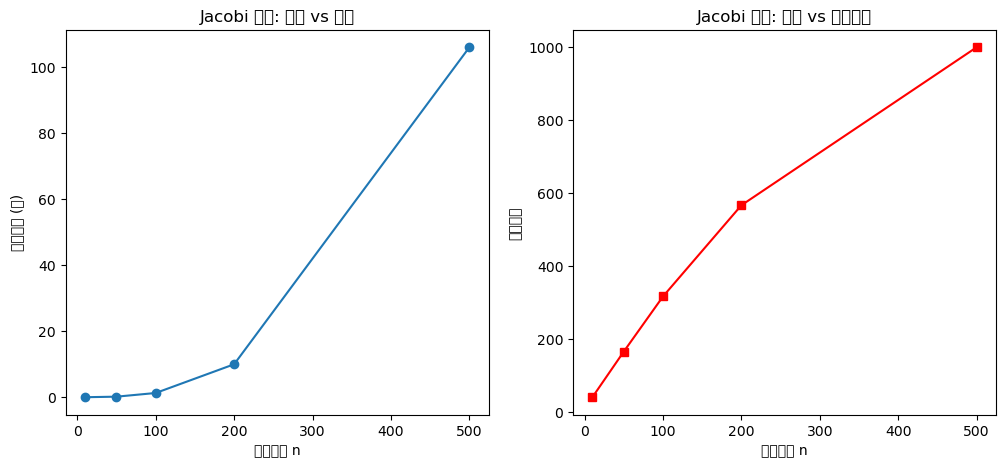

In [6]:
import time
import numpy as np
import matplotlib.pyplot as plt

# 定义不同的问题规模
n_values = [10, 50, 100, 200, 500]
times = []
iterations_list = []

for n in n_values:
    # 构造一个严格对角占优的随机矩阵，保证 Jacobi 收敛
    A = np.random.rand(n, n)
    for i in range(n):
        A[i, i] = np.sum(np.abs(A[i, :])) + 1.0  # 让对角线绝对大于其他行元素之和
    b = np.random.rand(n)
    x0 = np.zeros(n)
    
    # 计时开始
    start_time = time.time()
    x, iters = jacobi(A, b, x0, tol=1e-6, max_iter=1000)
    end_time = time.time()
    
    run_time = end_time - start_time
    times.append(run_time)
    iterations_list.append(iters)
    print(f"n={n:3d} | 时间={run_time:.4f}秒 | 迭代次数={iters}")

# 画图：规模 vs 时间
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(n_values, times, 'o-')
plt.xlabel('矩阵大小 n')
plt.ylabel('运行时间 (秒)')
plt.title('Jacobi 迭代: 规模 vs 时间')

# 画图：规模 vs 迭代次数
plt.subplot(1, 2, 2)
plt.plot(n_values, iterations_list, 's-', color='red')
plt.xlabel('矩阵大小 n')
plt.ylabel('迭代次数')
plt.title('Jacobi 迭代: 规模 vs 迭代次数')
plt.show()

n= 10 | 时间=0.0046秒 | 迭代次数=49
n= 50 | 时间=0.2539秒 | 迭代次数=173
n=100 | 时间=1.2608秒 | 迭代次数=314
n=200 | 时间=9.3414秒 | 迭代次数=565
n=500 | 时间=105.5493秒 | 迭代次数=1000


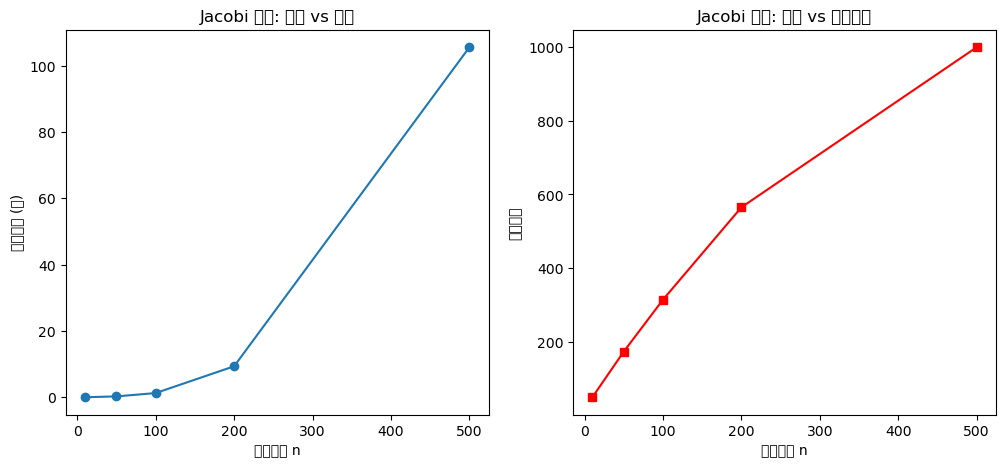

In [7]:
import time
import numpy as np
import matplotlib.pyplot as plt

# 定义不同的问题规模
n_values = [10, 50, 100, 200, 500]
times = []
iterations_list = []

for n in n_values:
    # 构造一个严格对角占优的随机矩阵，保证 Jacobi 收敛
    A = np.random.rand(n, n)
    for i in range(n):
        A[i, i] = np.sum(np.abs(A[i, :])) + 1.0  # 让对角线绝对大于其他行元素之和
    b = np.random.rand(n)
    x0 = np.zeros(n)
    
    # 计时开始
    start_time = time.time()
    x, iters = jacobi(A, b, x0, tol=1e-6, max_iter=1000)
    end_time = time.time()
    
    run_time = end_time - start_time
    times.append(run_time)
    iterations_list.append(iters)
    print(f"n={n:3d} | 时间={run_time:.4f}秒 | 迭代次数={iters}")

# 画图：规模 vs 时间
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(n_values, times, 'o-')
plt.xlabel('矩阵大小 n')
plt.ylabel('运行时间 (秒)')
plt.title('Jacobi 迭代: 规模 vs 时间')

# 画图：规模 vs 迭代次数
plt.subplot(1, 2, 2)
plt.plot(n_values, iterations_list, 's-', color='red')
plt.xlabel('矩阵大小 n')
plt.ylabel('迭代次数')
plt.title('Jacobi 迭代: 规模 vs 迭代次数')
plt.show()

2.Gauss-Seidel 迭代解 A x = b。

In [4]:
import numpy as np
def gauss_seidel_demo(A, b, x0, tol=1e-10, max_iter=1000):
    A = np.asarray(A, dtype=float)
    b = np.asarray(b, dtype=float)
    x = np.asarray(x0, dtype=float).copy()
    n = len(b)
    for k in range(1, max_iter + 1):
        x_old = x.copy()
        for i in range(n):
            sum_new = A[i, :i] @ x[:i] 
            sum_old = A[i, i+1:] @ x[i+1:]
            x[i] = (b[i] - sum_new - sum_old) / A[i, i]
        error = np.max(np.abs(x - x_old))
        if error < tol:
            return x, k
    return x, max_iter
# ================= 实际测试 =================
print("求解方程组:")
print("4*x1 + x2 = 1")
print("x1 + 3*x2 = 2")
print("=" * 50)
A = [[4, 1],
     [1, 3]]
b = [1, 2]
x0 = [0, 0]
x_final, k_final = gauss_seidel_demo(A, b, x0, tol=1e-6, max_iter=5)
print(f"\n最终近似解: {x_final}")

求解方程组:
4*x1 + x2 = 1
x1 + 3*x2 = 2

最终近似解: [0.09091676 0.63636108]


3.SOR（逐次超松弛）迭代解 A x = b。

In [5]:
import numpy as np
def sor_demo(A, b, omega, x0, max_iter=6):
    A = np.asarray(A, dtype=float)
    b = np.asarray(b, dtype=float)
    x = np.asarray(x0, dtype=float).copy()
    n = len(b)
    for k in range(1, max_iter + 1):
        x_old = x.copy()
        for i in range(n):
            sum_new = A[i, :i] @ x[:i] 
            sum_old = A[i, i+1:] @ x[i+1:]
            gs_val = (b[i] - sum_new - sum_old) / A[i, i]
            old_xi = x[i]
            x[i] = (1 - omega) * old_xi + omega * gs_val
        error = np.max(np.abs(x - x_old))
        if error < 1e-10:
            return x, k
    return x, max_iter
# 运行测试
A = [[4, 1], [1, 3]]
b = [1, 2]
x0 = [0, 0]
sor_demo(A, b, omega=1.2, x0=x0, max_iter=5)

(array([0.09056333, 0.63630254]), 5)